# Лабораторная №2. Классификация Titanic

Цель — предсказать `Survived`: 1 — выжил, 0 — не выжил.
[Задание курса](https://github.com/lesopylka/ml_course_mai/tree/main/classification) · [Датасет Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset).

Сравнил Dummy и пять классификаторов по Accuracy, Precision, Recall и **F1 класса 1**.
Целевой порог качества — **F1 > 0.70**.

Использовал улучшенные признаки и настройки, выбранные на train-CV.

## 1. Окружение

Зафиксировал `random_state=42`, split 80/20 и пять CV-фолдов train для выбора моделей.
Seed обеспечивает повторяемость, а не улучшение качества.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, TunedThresholdClassifierCV, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, make_scorer
RANDOM_STATE = 42
BASE = Path.cwd()
if not (BASE / 'data' / 'Titanic-Dataset.csv').exists():
    BASE = BASE / 'classification'
RESULTS = BASE / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
F1_SCORER = make_scorer(f1_score, pos_label=1, zero_division=0)
def show_plot(name):
    plt.savefig(FIGURES / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
def metrics(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            'Recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            'F1': f1_score(y_true, y_pred, pos_label=1, zero_division=0)}

## 2. Данные и первичный анализ

Проверил структуру, пропуски, дубликаты и баланс цели. Связи признаков с исходом исследовал только на train.

In [2]:
DATA_PATH = BASE / 'data' / 'Titanic-Dataset.csv'
data = pd.read_csv(DATA_PATH)
assert data['PassengerId'].is_unique
assert not data['Survived'].isna().any()
assert set(data['Survived'].unique()) == {0, 1}
display(data.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Пример строк:** одна строка соответствует пассажиру; Survived — целевой исход.

In [3]:
schema = pd.DataFrame({'type': data.dtypes.astype(str), 'missing': data.isna().sum(), 'unique': data.nunique()})
display(schema)

,type,missing,unique
PassengerId,int64,0,891
Survived,int64,0,2
Pclass,int64,0,3
Name,str,0,891
Sex,str,0,2
Age,float64,177,88
SibSp,int64,0,7
Parch,int64,0,7
Ticket,str,0,681
Fare,float64,0,248


**Вывод:** пропуски есть в Age (177), Cabin (687) и Embarked (2); Cabin особенно неполон.

In [4]:
print('Размер:', data.shape, 'Полные дубликаты:', data.duplicated().sum())
display(data['Survived'].value_counts().sort_index().rename('count').to_frame())

Размер: (891, 12) Полные дубликаты: 0


,count
Survived,
0,549
1,342


**Вывод:** 891 пассажир, полных дубликатов нет; выжили 38.4%. Из-за преобладания класса 0 одной Accuracy недостаточно.

### Признаки и разбиение

К исходным Pclass, Sex, Age, SibSp, Parch, Fare, Embarked добавил:

- **Title** — обращение Mr/Mrs/Miss/Master/Other, извлечённое из имени;
- **FamilySize = SibSp + Parch + 1**, **IsAlone** — нет указанных в SibSp/Parch родственников;
- **FarePerPerson = Fare / FamilySize** — условная стоимость на члена семьи, не точная цена личного билета;
- **AgeMissing** — отсутствует возраст.

Fare и FarePerPerson преобразовал через log1p. Эти операции выполняются по каждой строке и не используют цель.
Само имя, ID, билет и каюту исключил; Title — общая категория, а не идентификатор человека.
Pclass рассматривал как категорию. Стратификация сохраняет доли классов; для моделей использовал одинаковые split и пять CV-фолдов.
Разных пассажиров с одинаковыми характеристиками не удалял; связи между семьями ограничивают переносимость оценки.

In [5]:
RAW_NUMERIC = ['Age', 'SibSp', 'Parch', 'Fare']
RAW_FEATURES = RAW_NUMERIC + ['Pclass', 'Sex', 'Embarked']
NUMERIC = RAW_NUMERIC + ['FamilySize', 'IsAlone', 'FarePerPerson', 'AgeMissing']
CATEGORICAL = ['Pclass', 'Sex', 'Embarked', 'Title']
FEATURES = NUMERIC + CATEGORICAL
EXCLUDED = ['PassengerId', 'Name', 'Ticket', 'Cabin', 'Survived']
def make_features(frame):
    X = frame[['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked']].copy()
    title = frame.Name.str.extract(r',\s*([^.]*)\.', expand=False).str.strip()
    title = title.replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    X['Title'] = title.where(title.isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Other')
    X['FamilySize'] = frame.SibSp + frame.Parch + 1
    X['IsAlone'] = (X.FamilySize == 1).astype(int)
    X['FarePerPerson'] = frame.Fare / X.FamilySize
    X['AgeMissing'] = frame.Age.isna().astype(int)
    X['Fare'] = np.log1p(X.Fare)
    X['FarePerPerson'] = np.log1p(X.FarePerPerson)
    return X
X = make_features(data)[FEATURES]
y = data.Survived.copy()
for col in ['Title', 'FamilySize', 'IsAlone', 'FarePerPerson', 'AgeMissing']:
    data[col] = X[col]
assert not set(EXCLUDED) & set(X.columns)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(data)
split = pd.DataFrame({'PassengerId': data.PassengerId, 'Survived': y,
                      'split': np.where(data.index.isin(X_train.index), 'train', 'test')})
split.to_csv(RESULTS / 'split.csv', index=False)
display(split.groupby('split').agg(n=('Survived', 'size'), survived_rate=('Survived', 'mean')))

,n,survived_rate
split,,
test,179,0.3855
train,712,0.3834


**Вывод:** train — 712, test — 179 пассажиров; доли выживших близки (около 38%).

In [6]:
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train))
fold_rows = []
for fold, (fit_idx, val_idx) in enumerate(cv):
    assert set(fit_idx).isdisjoint(val_idx)
    for pos in val_idx:
        fold_rows.append({'PassengerId': int(data.loc[X_train.index[pos], 'PassengerId']), 'fold': fold})
pd.DataFrame(fold_rows).to_csv(RESULTS / 'cv_folds.csv', index=False)

### Анализ обучающей выборки

In [7]:
train = data.loc[X_train.index].copy()
display(train[RAW_NUMERIC].describe())

,Age,SibSp,Parch,Fare
count,575.0000,712.0000,712.0000,712.0000
mean,29.8077,0.4930,0.3904,31.8198
std,14.4852,1.0607,0.8381,48.0591
min,0.4200,0.0000,0.0000,0.0000
25%,21.0000,0.0000,0.0000,7.8958
50%,28.5000,0.0000,0.0000,14.4542
75%,39.0000,1.0000,0.0000,31.0000
max,80.0000,8.0000,6.0000,512.3292


**Вывод:** Fare имеет большой разброс и значения далеко выше медианы; масштаб отличается от Age и семейных счётчиков.

In [8]:
display(train[FEATURES].isna().sum().rename('train_missing').to_frame())

,train_missing
Age,137
SibSp,0
Parch,0
Fare,0
FamilySize,0
IsAlone,0
FarePerPerson,0
AgeMissing,0
Pclass,0
Sex,0


**Вывод:** среди выбранных признаков обнаружил пропуски только в Age и Embarked; значения заполнения рассчитал только на train.

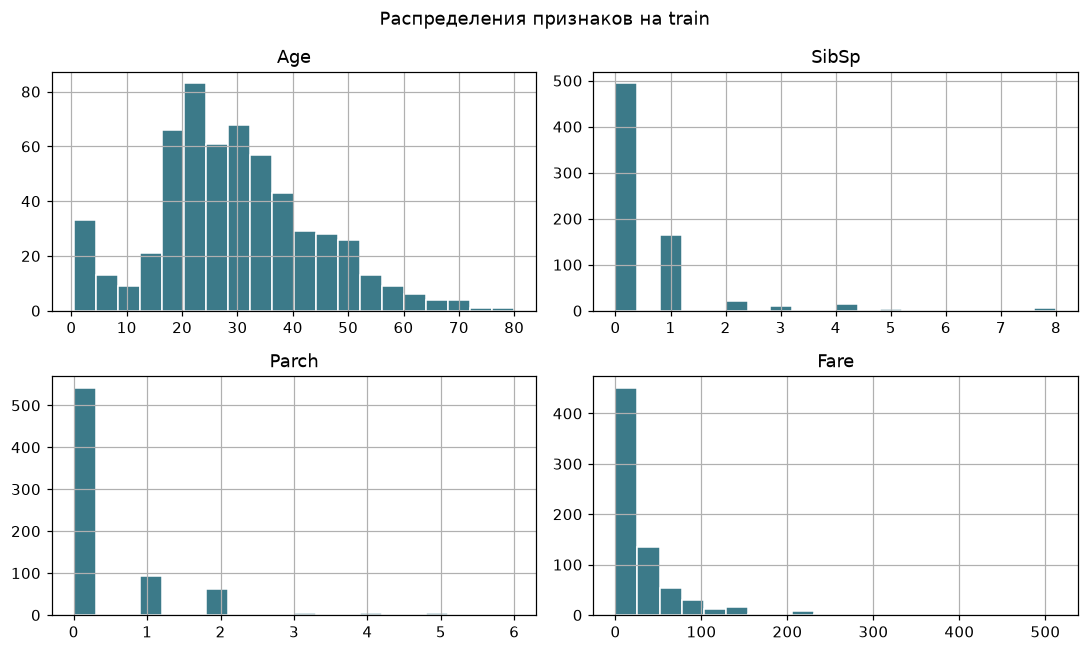

In [9]:
train[RAW_NUMERIC].hist(figsize=(10, 6), bins=20, color='#3c7a89', edgecolor='white')
plt.suptitle('Распределения признаков на train')
plt.tight_layout()
show_plot('01_distributions')

**Вывод:** у исходного Fare длинный правый хвост, поэтому для моделей использовал log1p; у SibSp/Parch чаще небольшие значения. Для Age использовал устойчивое к крайним значениям заполнение медианой train.

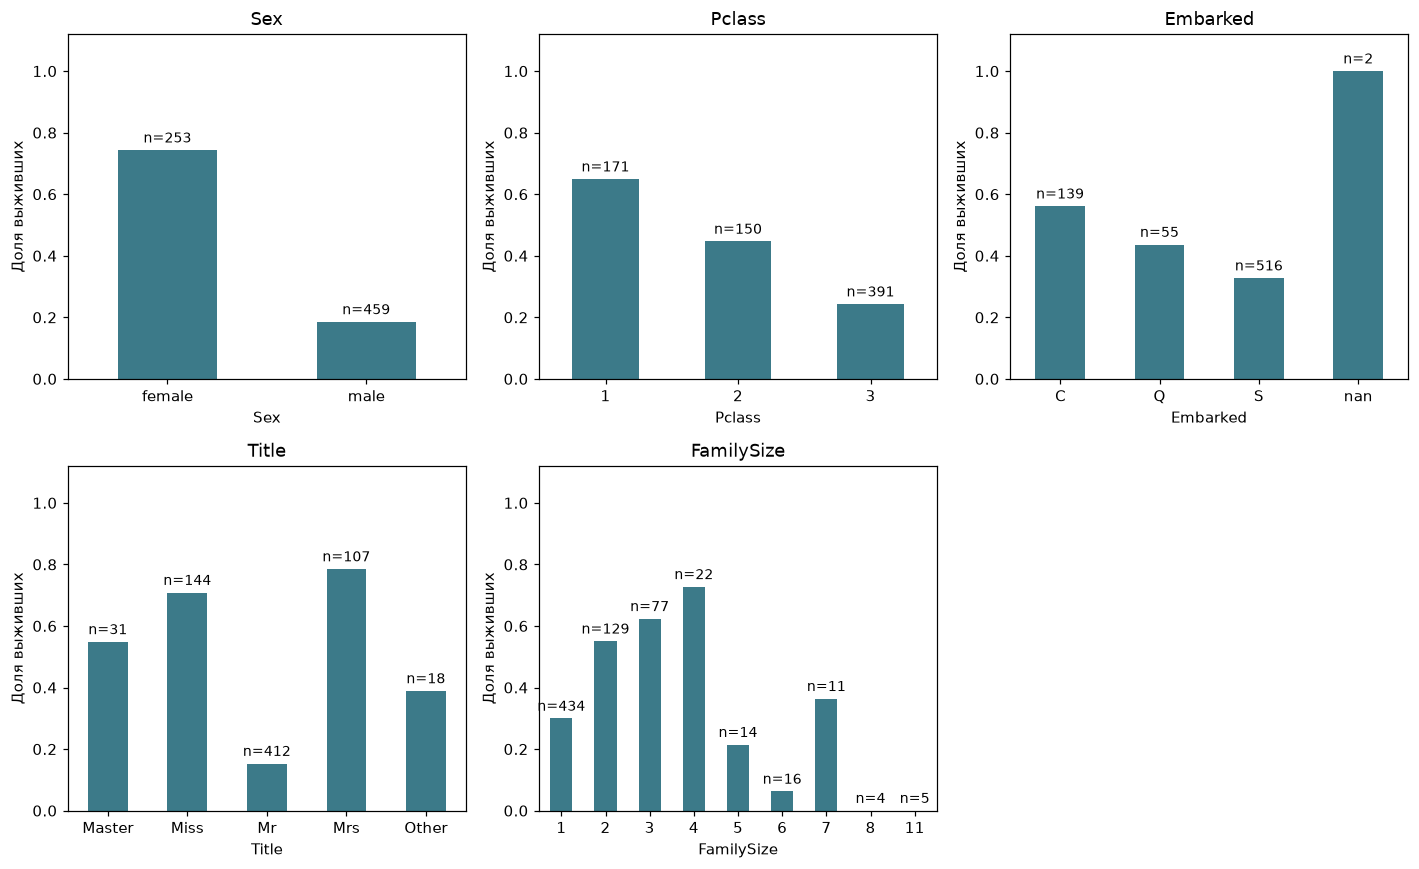

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
eda_groups = {}
for ax, col in zip(axes.ravel(), ['Sex', 'Pclass', 'Embarked', 'Title', 'FamilySize']):
    summary = train.groupby(col, dropna=False).Survived.agg(['mean', 'size'])
    eda_groups[col] = summary
    summary['mean'].plot.bar(ax=ax, color='#3c7a89', rot=0)
    ax.set_title(col)
    ax.set_ylabel('Доля выживших')
    ax.set_ylim(0, 1.12)
    for i, (_, row) in enumerate(summary.iterrows()):
        ax.text(i, row['mean'] + .025, f"n={int(row['size'])}", ha='center', fontsize=9)
axes.ravel()[-1].set_visible(False)
plt.tight_layout()
show_plot('02_group_survival')

Все пять диаграмм построил только по train. Высота столбца — доля реально выживших в группе: число Survived=1, делённое на размер группы. Это описание известных исходов, а не прогноз модели. Подпись n показывает число пассажиров в группе.

**Замечания по группам:**

- **Sex:** выжили 74.3% женщин и 18.5% мужчин. Пол заметно связан с исходом.
- **Pclass:** доля выживших в первом классе — 64.9%, во втором — 44.7%, в третьем — 24.3%. Класс билета может быть полезным признаком.
- **Embarked:** различия портов могут отражать состав пассажиров по полу и классу билета. Столбец nan — не отдельный порт: это два пассажира с пропуском, оба выжили. Их 100% нельзя считать устойчивой закономерностью.
- **Title:** у Mrs выжили 78.5%, у Miss — 70.8%, у Mr — 15.3%, у Master — 54.8%. Обращение связано с полом, возрастной группой и семейным положением; оно частично повторяет информацию Sex. Для редких обращений оценки менее устойчивы.
- **FamilySize:** у пассажиров без указанных родственников доля выживших — 30.0%; у семей из 2–4 человек — примерно 55–73%. Для более крупных семей результаты неоднородны. Группы размера 8 и 11 представлены всего четырьмя и пятью пассажирами: нулевая доля выживших здесь не означает, что исход всегда будет таким.

**Вывод:** пол, класс билета, обращение и размер семьи связаны с выживанием и могут помогать прогнозу; полезность проверил моделями через CV. Различия долей не доказывают причинность. При интерпретации учёл размер групп и пересечение информации между признаками.

## 3. Baseline, метрики и подготовка признаков

Числовые пропуски заполнил медианой, категории — модой, затем применил one-hot.
Параметры преобразований определил внутри `Pipeline`: только на train, при CV — на обучающей части фолда.

Для SVM/KNN стандартизировал числовые признаки: иначе Fare может доминировать в расстояниях.
One-hot имеет масштаб 0/1; деревьям стандартизация обычно не нужна, поскольку они используют отдельные пороги.

- **Accuracy** = (TP + TN) / N — доля верных прогнозов.
- **Precision** = TP / (TP + FP) — доля выживших среди предсказанных выживших.
- **Recall** = TP / (TP + FN) — доля найденных выживших.
- **F1** = 2PR / (P + R) — баланс Precision и Recall; TN напрямую не учитывает.

**FP:** погибшему предсказали выживание. **FN:** выжившему предсказали гибель.
Если положительных прогнозов нет, Precision принял равной 0 (`zero_division=0`).

Baseline — `DummyClassifier(strategy="most_frequent")`: всегда предсказывает самый частый класс train. Сначала рассчитал CV; итоговые test-метрики получил вместе со всеми моделями.

In [11]:
#создаем схему подготовки признаков перед обучением модели.
def preprocessor(scale=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        numeric_steps.append(('scaler', StandardScaler()))
    numeric = Pipeline(numeric_steps)
    categorical = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([
        ('num', numeric, NUMERIC), ('cat', categorical, CATEGORICAL)],
        remainder='drop', verbose_feature_names_out=False)
def pipeline(model, scale=False):
    return Pipeline([('prepare', preprocessor(scale)), ('model', model)])

In [12]:
baseline = pipeline(DummyClassifier(strategy='most_frequent'))
baseline_cv = cross_val_score(baseline, X_train, y_train, cv=cv, scoring=F1_SCORER, n_jobs=1)
baseline.fit(X_train, y_train)
print('Baseline CV F1:', baseline_cv.mean())
print('Прогнозируемый класс:', int(y_train.mode().iloc[0]))

Baseline CV F1: 0.0
Прогнозируемый класс: 0


**Вывод:** Dummy предсказывает 0 всем: Accuracy отражает долю большинства, но Recall и F1 выживших равны нулю.

## 4. Модели и кросс-валидация

Дерево делит объекты по порогам; лес усредняет деревья, бустинг добавляет их последовательно.
SVM строит нелинейную границу, KNN голосует по ближайшим пассажирам; в KNN использовал манхэттенское расстояние.

Настройки выбрал в предварительном эксперименте на train-CV.
Ниже сравнил модели на одинаковых пяти фолдах. Для бустинга и KNN пороги выбрал по F1 внутренней 3-fold CV.
Значения 0.35 и 0.45 получил на train; остальные модели используют стандартный predict.
`CV_std` — разброс по фолдам, а близкие средние не доказывают устойчивого превосходства.

In [13]:
specifications = {
    'Decision Tree': pipeline(DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=RANDOM_STATE)),
    'Random Forest': pipeline(RandomForestClassifier(n_estimators=250, max_depth=8, min_samples_leaf=1, random_state=RANDOM_STATE, n_jobs=1)),
    'Gradient Boosting': pipeline(GradientBoostingClassifier(n_estimators=200, learning_rate=.05, max_depth=3, random_state=RANDOM_STATE)),
    'SVM': pipeline(SVC(C=2, gamma=.05, kernel='rbf'), scale=True),
    'KNN': pipeline(KNeighborsClassifier(n_neighbors=7, weights='uniform', p=1), scale=True)}
models = {'Dummy': baseline}
cv_rows = [{'model': 'Dummy', 'CV_F1': baseline_cv.mean(), 'CV_std': baseline_cv.std(), 'threshold': .5, 'params': '{}'}]
for name, estimator in specifications.items():
    if name in ['Gradient Boosting', 'KNN']:
        estimator = TunedThresholdClassifierCV(estimator, scoring=F1_SCORER,
            thresholds=np.linspace(.2, .65, 19),
            cv=StratifiedKFold(3, shuffle=True, random_state=17),
            response_method='predict_proba', n_jobs=1)
    scores = cross_val_score(estimator, X_train, y_train, cv=cv, scoring=F1_SCORER, n_jobs=1, error_score='raise')
    pd.DataFrame({'fold': range(5), 'F1': scores}).to_csv(
        RESULTS / f'cv_{name.lower().replace(" ", "_")}.csv', index=False)
    estimator.fit(X_train, y_train)
    models[name] = estimator
    threshold = float(estimator.best_threshold_) if name in ['Gradient Boosting', 'KNN'] else (0.0 if name == 'SVM' else .5)
    params = {k: v for k, v in specifications[name].get_params().items()
              if k.startswith('model__') and k in ['model__max_depth', 'model__min_samples_leaf', 'model__n_estimators', 'model__learning_rate', 'model__C', 'model__gamma', 'model__n_neighbors', 'model__p', 'model__weights']}
    cv_rows.append({'model': name, 'CV_F1': scores.mean(), 'CV_std': scores.std(),
                    'threshold': threshold, 'params': json.dumps(params, ensure_ascii=False)})
cv_table = pd.DataFrame(cv_rows).set_index('model').sort_values('CV_F1', ascending=False)
cv_table.to_csv(RESULTS / 'cv_summary.csv')
BEST_NAME = cv_table.drop(index='Dummy').index[0]
display(cv_table[['CV_F1', 'CV_std', 'threshold']])

,CV_F1,CV_std,threshold
model,,,
Decision Tree,0.7780,0.0530,0.50
Gradient Boosting,0.7745,0.0353,0.35
SVM,0.7656,0.0297,0.00
Random Forest,0.7641,0.0344,0.50
KNN,0.7564,0.0379,0.45
Dummy,0.0000,0.0000,0.50


**Вывод:** по CV выбрал Decision Tree; разница с бустингом мала относительно разброса. Пороги бустинга/KNN подобрал внутри train; максимум на test не использовал для выбора основной модели.

## 5. Оценка на test

После фиксации настроек оценил все модели на одном test. Основную модель выбрал по CV, а не по test-метрикам.

In [14]:
test_predictions = pd.DataFrame({'PassengerId': data.loc[X_test.index, 'PassengerId'], 'y_true': y_test})
test_rows, train_rows, matrices = [], [], {}
for name, estimator in models.items():
    pred = estimator.predict(X_test)
    train_pred = estimator.predict(X_train)
    test_predictions[name] = pred
    test_rows.append({'model': name, **metrics(y_test, pred)})
    train_rows.append({'model': name, **metrics(y_train, train_pred)})
    matrices[name] = confusion_matrix(y_test, pred, labels=[0, 1])
test_table = pd.DataFrame(test_rows).set_index('model')
train_table = pd.DataFrame(train_rows).set_index('model')
test_table['F1_above_0.70'] = test_table['F1'] > .70
test_table.to_csv(RESULTS / 'test_metrics.csv')
train_table.to_csv(RESULTS / 'train_metrics.csv')
test_predictions.to_csv(RESULTS / 'test_predictions.csv', index=False)
display(test_table)

,Accuracy,Precision,Recall,F1,F1_above_0.70
model,,,,,
Dummy,0.6145,0.0000,0.0000,0.0000,False
Decision Tree,0.8212,0.7534,0.7971,0.7746,True
Random Forest,0.8324,0.8197,0.7246,0.7692,True
Gradient Boosting,0.7877,0.7013,0.7826,0.7397,True
SVM,0.8436,0.8361,0.7391,0.7846,True
KNN,0.8156,0.7903,0.7101,0.7481,True


**Вывод:** F1 > 0.70 у Decision Tree, Random Forest, Gradient Boosting, SVM, KNN. У выбранной по CV модели Decision Tree test F1 = 0.775. Все обученные модели лучше Dummy.

In [15]:
comparison = pd.DataFrame({'Train F1': train_table.F1, 'CV F1': cv_table.CV_F1, 'Test F1': test_table.F1})
display(comparison)

,Train F1,CV F1,Test F1
model,,,
Decision Tree,0.7949,0.7780,0.7746
Dummy,0.0000,0.0000,0.0000
Gradient Boosting,0.8725,0.7745,0.7397
KNN,0.8094,0.7564,0.7481
Random Forest,0.9042,0.7641,0.7692
SVM,0.7806,0.7656,0.7846


**Вывод:** наибольший разрыв train/CV у Random Forest; это признак возможного переобучения. Обучающие метрики не заменяют CV/test.

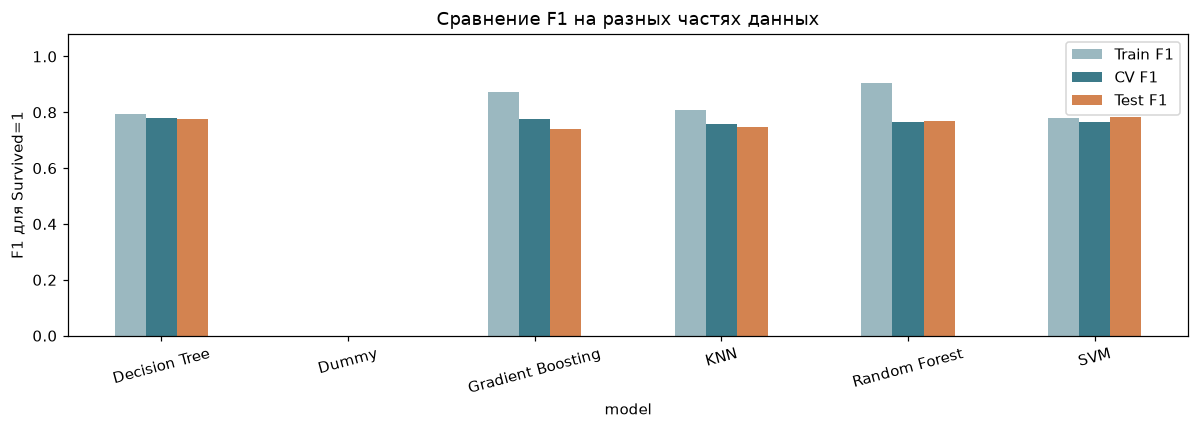

In [16]:
comparison.plot.bar(figsize=(11, 4), ylim=(0, 1.08), color=['#9bb8c0', '#3c7a89', '#d38350'], rot=15)
plt.title('Сравнение F1 на разных частях данных')
plt.ylabel('F1 для Survived=1')
plt.tight_layout()
show_plot('03_model_comparison')

**Вывод:** дерево: train F1=0.795, CV=0.778, test=0.775. У леса test F1=0.769, у бустинга — 0.740. Порядок на CV и test различается: модели по-разному обобщают данные, а выборка невелика.

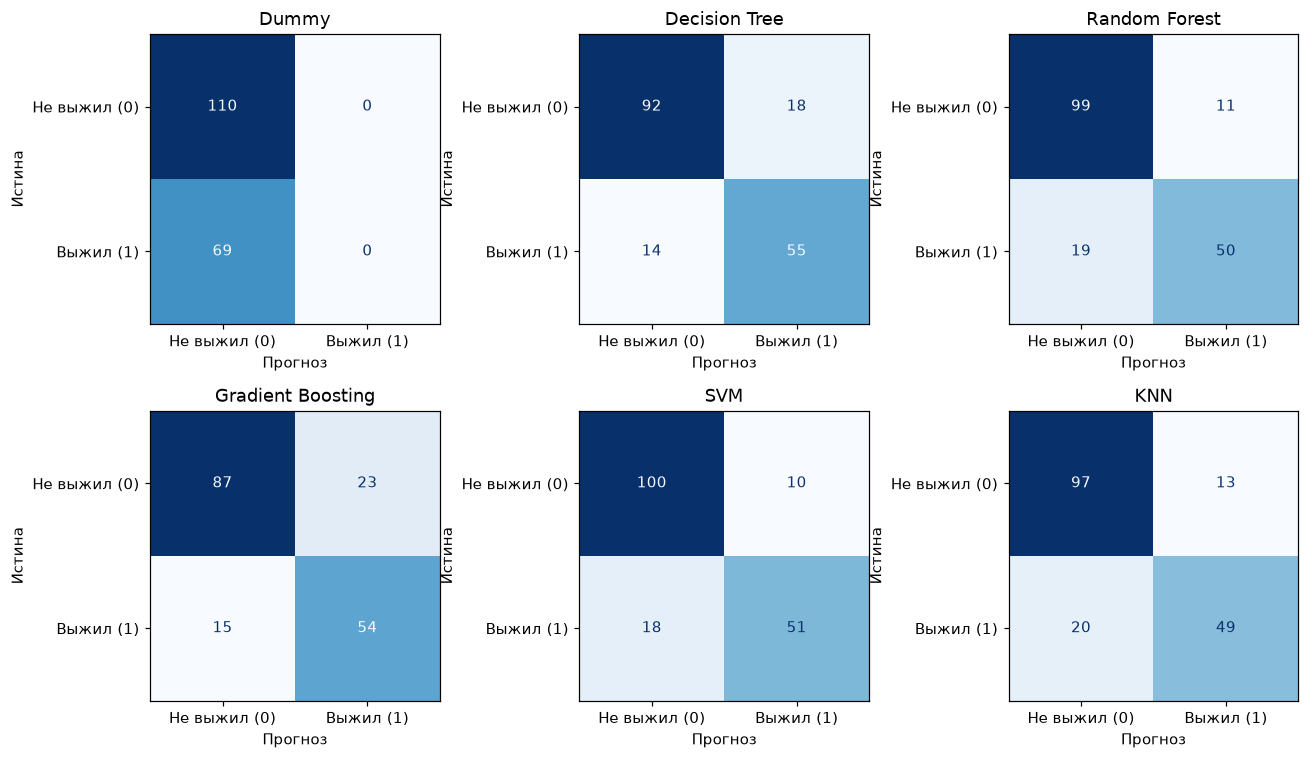

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (name, cm) in zip(axes.ravel(), matrices.items()):
    ConfusionMatrixDisplay(cm, display_labels=['Не выжил (0)', 'Выжил (1)']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
    ax.set_xlabel('Прогноз')
    ax.set_ylabel('Истина')
plt.tight_layout()
show_plot('04_confusion_matrices')

**Вывод:** Dummy: FP=0, FN=69; Decision Tree: FP=18, FN=14; Random Forest: FP=11, FN=19; Gradient Boosting: FP=23, FN=15; SVM: FP=10, FN=18; KNN: FP=13, FN=20. Часть моделей чаще допускает FP, часть — FN. Для бустинга использовал порог 0.35, позволяющий чаще предсказывать выживание. У KNN пороги 0.45 и 0.50 дают одинаковые итоговые классы: при семи равноправных соседях нужны минимум четыре голоса за выживание. Сопоставил Precision и Recall.

## 6. Важность признаков

`feature_importances_` оценивает уменьшение критерия разбиений на train.
Суммировал one-hot важности до исходных признаков. Возможны предпочтение признаков с множеством порогов
и перераспределение важностей между связанными признаками.

In [18]:
importance_columns = {}
for name in ['Decision Tree', 'Random Forest', 'Gradient Boosting']:
    estimator = models[name]
    if isinstance(estimator, TunedThresholdClassifierCV):
        estimator = estimator.estimator_
    names = estimator.named_steps['prepare'].get_feature_names_out()
    values = estimator.named_steps['model'].feature_importances_
    raw = pd.Series(values, index=names, name='importance')
    raw.to_csv(RESULTS / f'importance_encoded_{name.lower().replace(" ", "_")}.csv')
    grouped = {col: 0.0 for col in FEATURES}
    for feature, value in raw.items():
        original = next(col for col in FEATURES if feature == col or feature.startswith(col + '_'))
        grouped[original] += float(value)
    importance_columns[name] = grouped
importance = pd.DataFrame(importance_columns)
importance.to_csv(RESULTS / 'feature_importance.csv')
display(importance.sort_values('Random Forest', ascending=False))

,Decision Tree,Random Forest,Gradient Boosting
Sex,0.0000,0.2272,0.0434
Title,0.6673,0.1999,0.4563
FarePerPerson,0.0988,0.1274,0.1325
Fare,0.0042,0.1160,0.0802
Age,0.0000,0.0999,0.0975
Pclass,0.1501,0.0888,0.1121
FamilySize,0.0796,0.0443,0.0549
Embarked,0.0000,0.0312,0.0178
SibSp,0.0000,0.0264,0.0041
Parch,0.0000,0.0172,0.0002


**Вывод:** лидеры важности: Decision Tree — Title; Random Forest — Sex; Gradient Boosting — Title. Title и Sex содержат связанную информацию; важность между ними зависит от алгоритма.

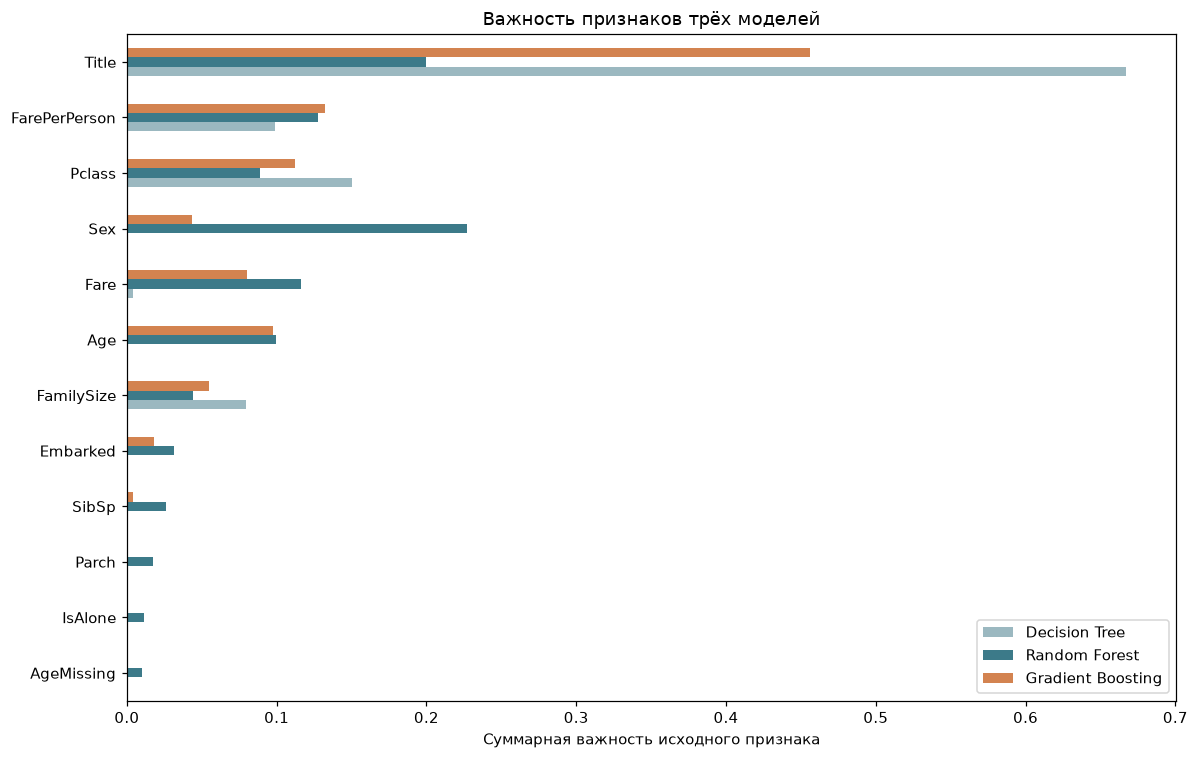

In [19]:
importance.loc[importance.mean(axis=1).sort_values().index].plot.barh(figsize=(11, 7), color=['#9bb8c0', '#3c7a89', '#d38350'])
plt.xlabel('Суммарная важность исходного признака')
plt.title('Важность признаков трёх моделей')
plt.tight_layout()
show_plot('05_feature_importance')

**Вывод:** Decision Tree: Title, Pclass, FarePerPerson; Random Forest: Sex, Title, FarePerPerson; Gradient Boosting: Title, FarePerPerson, Pclass. Это согласуется с различиями по полу, Title, классу и семье в EDA. Важность не задаёт направление связи и не доказывает причинность.

## 7. Анализ ошибок лучшей модели

Разобрал модель, выбранную по CV. Анализ test-ошибок использовал для объяснения результата, без перенастройки.

In [20]:
best = models[BEST_NAME]
errors = data.loc[X_test.index, ['PassengerId'] + FEATURES + ['Survived']].copy()
errors['prediction'] = test_predictions[BEST_NAME]
errors['error'] = errors['Survived'] != errors['prediction']
errors['error_type'] = np.select([
    (errors.Survived == 0) & (errors.prediction == 1),
    (errors.Survived == 1) & (errors.prediction == 0)], ['FP', 'FN'], default='correct')
errors.to_csv(RESULTS / 'best_model_errors.csv', index=False)
tn, fp, fn, tp = matrices[BEST_NAME].ravel()
display(pd.DataFrame({'TN': [tn], 'FP': [fp], 'FN': [fn], 'TP': [tp]}, index=[BEST_NAME]))

,TN,FP,FN,TP
Decision Tree,92,18,14,55


**Вывод:** Decision Tree: FP=18, FN=14; чаще — FP. Precision=0.753, Recall=0.797. Сопоставление показывает, какие ошибки преобладают у выбранной модели.

In [21]:
errors['AgeGroup'] = pd.cut(errors.Age, bins=[-np.inf, 12, 18, 40, 60, np.inf],
                           labels=['0-12', '13-18', '19-40', '41-60', '61+']).astype('object').fillna('unknown')
group_rows = []
for col in ['Sex', 'Pclass', 'AgeGroup']:
    for value, group in errors.groupby(col, observed=True, dropna=False):
        group_rows.append({'feature': col, 'group': str(value), 'n': len(group),
                           'errors': int(group.error.sum()), 'error_rate': group.error.mean(),
                           'FP': int((group.error_type == 'FP').sum()),
                           'FN': int((group.error_type == 'FN').sum()),
                           'F1': f1_score(group.Survived, group.prediction, zero_division=0)})
group_errors = pd.DataFrame(group_rows)
group_errors.to_csv(RESULTS / 'group_errors.csv', index=False)
display(group_errors)

,feature,group,n,errors,error_rate,FP,FN,F1
0,Sex,female,61,12,0.1967,11,1,0.8800
1,Sex,male,118,20,0.1695,7,13,0.5238
2,Pclass,1,45,14,0.3111,8,6,0.7308
3,Pclass,2,34,3,0.0882,1,2,0.9231
4,Pclass,3,100,15,0.1500,9,6,0.7059
5,AgeGroup,0-12,14,1,0.0714,1,0,0.9333
6,AgeGroup,13-18,17,1,0.0588,1,0,0.9412
7,AgeGroup,19-40,79,16,0.2025,7,9,0.7500
8,AgeGroup,41-60,23,3,0.1304,2,1,0.8000
9,AgeGroup,61+,6,3,0.5000,2,1,0.4000


**Вывод:** female: FP=11, FN=1, ошибок 19.7%; male: FP=7, FN=13, ошибок 16.9%. По полу сравнил и долю ошибок, и их тип: состав положительного класса различается.

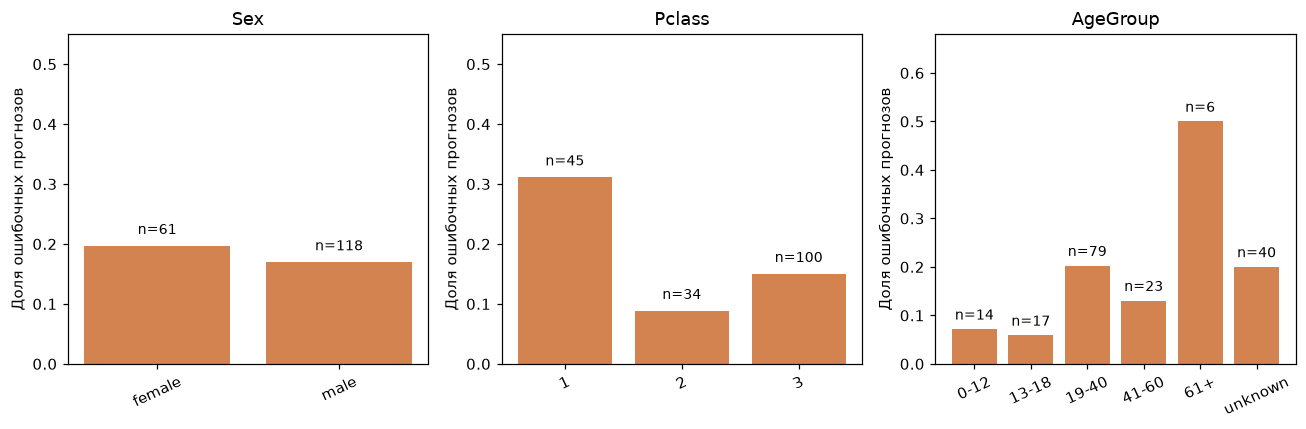

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ['Sex', 'Pclass', 'AgeGroup']):
    part = group_errors[group_errors.feature == col]
    ax.bar(part.group, part.error_rate, color='#d38350')
    ax.set_title(col)
    ax.set_ylim(0, min(1.15, max(.55, part.error_rate.max() + .18)))
    ax.set_ylabel('Доля ошибочных прогнозов')
    for i, row in enumerate(part.itertuples()):
        ax.text(i, row.error_rate + .02, f'n={row.n}', ha='center', fontsize=9)
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
show_plot('06_group_errors')

**Вывод:** среди групп с n≥15 выше доля ошибок: Pclass=1: 31.1% (14/45); AgeGroup=19-40: 20.3% (16/79); AgeGroup=unknown: 20.0% (8/40). Группы пересекаются; оценки маленьких групп нестабильны.

In [23]:
examples = pd.concat([errors[errors.error_type == kind].sort_values('PassengerId').head(3)
                      for kind in ['FP', 'FN']])
display(examples[['PassengerId', 'Survived', 'prediction', 'error_type', 'Sex', 'Pclass', 'Age', 'Fare', 'Title', 'FamilySize']])

,PassengerId,Survived,prediction,error_type,Sex,Pclass,Age,Fare,Title,FamilySize
38,39,0,1,FP,female,3,18.0,18.000,Miss,3
40,41,0,1,FP,female,3,40.0,9.475,Mrs,2
92,93,0,1,FP,male,1,46.0,61.175,Mr,2
17,18,1,0,FN,male,2,NaN,13.000,Mr,1
23,24,1,0,FN,male,1,28.0,35.500,Mr,1
55,56,1,0,FN,male,1,NaN,35.500,Mr,1


**Вывод:** для разбора выбрал первые по ID до трёх FP и FN; возраст неизвестен у 2 из 6 пассажиров. Даже одинаковые пол, обращение и класс билета не определяют индивидуальный исход.

In [24]:
examples.to_csv(RESULTS / 'error_examples.csv', index=False)

**ID 39 (FP):** в похожей train-группе (female, класс 3) выжили 50.0% из 116. Title=Miss, семья=3. Наблюдаемые признаки не описывают все обстоятельства спасения. Это возможное объяснение ошибки.

**ID 41 (FP):** в похожей train-группе (female, класс 3) выжили 50.0% из 116. Title=Mrs, семья=2. Наблюдаемые признаки не описывают все обстоятельства спасения. Это возможное объяснение ошибки.

**ID 93 (FP):** в похожей train-группе (male, класс 1) выжили 37.0% из 92. Title=Mr, семья=2. Наблюдаемые признаки не описывают все обстоятельства спасения. Это возможное объяснение ошибки.

**ID 18 (FN):** в похожей train-группе (male, класс 2) выжили 15.2% из 92. Title=Mr, семья=1. Дерево не использовало Age в разбиениях, поэтому пропуск возраста не объясняет этот прогноз. Правила по остальным признакам не позволили распознать выжившего пассажира.

**ID 24 (FN):** в похожей train-группе (male, класс 1) выжили 37.0% из 92. Title=Mr, семья=1. Наблюдаемые признаки не описывают все обстоятельства спасения. Это возможное объяснение ошибки.

**ID 56 (FN):** в похожей train-группе (male, класс 1) выжили 37.0% из 92. Title=Mr, семья=1. Дерево не использовало Age в разбиениях, поэтому пропуск возраста не объясняет этот прогноз. Правила по остальным признакам не позволили распознать выжившего пассажира.

In [25]:
for estimator in models.values():
    if isinstance(estimator, TunedThresholdClassifierCV):
        estimator = estimator.estimator_
    assert list(estimator.feature_names_in_) == FEATURES
    assert not set(estimator.feature_names_in_) & set(EXCLUDED)
    assert estimator.named_steps['prepare'].remainder == 'drop'
train_hashes = set(pd.util.hash_pandas_object(X_train, index=False).tolist())
same_features = pd.util.hash_pandas_object(X_test, index=False).isin(train_hashes)
print('Test-пассажиров с таким же набором выбранных признаков на train:', int(same_features.sum()))
print('Полных дубликатов исходной таблицы:', int(data.duplicated().sum()))

Test-пассажиров с таким же набором выбранных признаков на train: 35
Полных дубликатов исходной таблицы: 0


**Вывод:** цель и идентификаторы исключил, параметры преобразований определил на train. Совпадающие характеристики и семьи ограничивают переносимость оценки; эти проверки не исключают все возможные смещения.

In [26]:
joblib.dump(best, RESULTS / 'best_model.joblib')
versions = {name: importlib.metadata.version(name) for name in
            ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'joblib', 'nbformat', 'nbclient', 'nbconvert', 'ipykernel']}
metadata = {
    'source': 'https://www.kaggle.com/datasets/yasserh/titanic-dataset',
    'course': 'https://github.com/lesopylka/ml_course_mai',
    'sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'random_state': RANDOM_STATE, 'test_size': .2,
    'n_train': len(X_train), 'n_test': len(X_test), 'features': FEATURES,
    'excluded': EXCLUDED, 'selection': 'max mean train CV binary F1, five stratified folds',
    'best_model': BEST_NAME, 'best_params': json.loads(cv_table.loc[BEST_NAME, 'params']),
    'classification_thresholds': cv_table['threshold'].to_dict(),
    'feature_builder': 'make_features from titanic_features.py; raw Name used only for Title',
    'numeric_features': NUMERIC,
    'feature_engineering': ['Title', 'FamilySize', 'IsAlone', 'FarePerPerson', 'AgeMissing', 'log1p Fare/FarePerPerson'],
    'evaluation_status': 'Research revision on previously inspected test; no fresh independent evaluation',
    'test_feature_matches_train': int(same_features.sum()),
    'python': platform.python_version(), 'versions': versions}
(RESULTS / 'experiment.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
(BASE / 'requirements-lab02.txt').write_text('\n'.join(f'{k}=={v}' for k, v in versions.items()) + '\n', encoding='utf-8')

149

## 8. Итоги

**По CV выбрал Decision Tree:** F1=0.778. На test: Accuracy=0.821, Precision=0.753, Recall=0.797, F1=0.775. Все пять обученных моделей имеют F1 > 0.70 и превосходят Dummy. У основной модели FP=18, FN=14. Важности и ошибки разобрал, результаты сохранил.

### Доработка решения

В первом варианте дерево (F1=0.682), бустинг (0.672) и KNN (0.688) не достигали 0.70.
Добавил Title, размер семьи, признак одиночного путешествия, условную стоимость на члена семьи и индикатор пропуска возраста; к стоимости применил log1p.
У дерева изменил глубину и размер листа, у леса ограничил глубину, у бустинга увеличил глубину и число деревьев,
у SVM усилил регуляризацию. В KNN уменьшил число соседей и перешёл к манхэттенскому расстоянию.
Пороги бустинга и KNN подобрал внутри train-CV: 0.35 и 0.45.

После доработки F1 на test: дерево — **0.775**, лес — **0.769**, бустинг — **0.740**, SVM — **0.785**, KNN — **0.748**.
Вклад каждого изменения отдельно не измерял. Сравнение выполнил на той же test-выборке: это оценка доработки, а не новая независимая проверка.
В предварительном поиске не использовал полностью вложенную CV, поэтому его CV-оценки могут быть оптимистичными.